In [565]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import  StandardScaler
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from scipy import stats
from sklearn.pipeline import Pipeline
import joblib   

In [566]:
df = pd.read_csv('housing.csv')

In [567]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [568]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [569]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [570]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

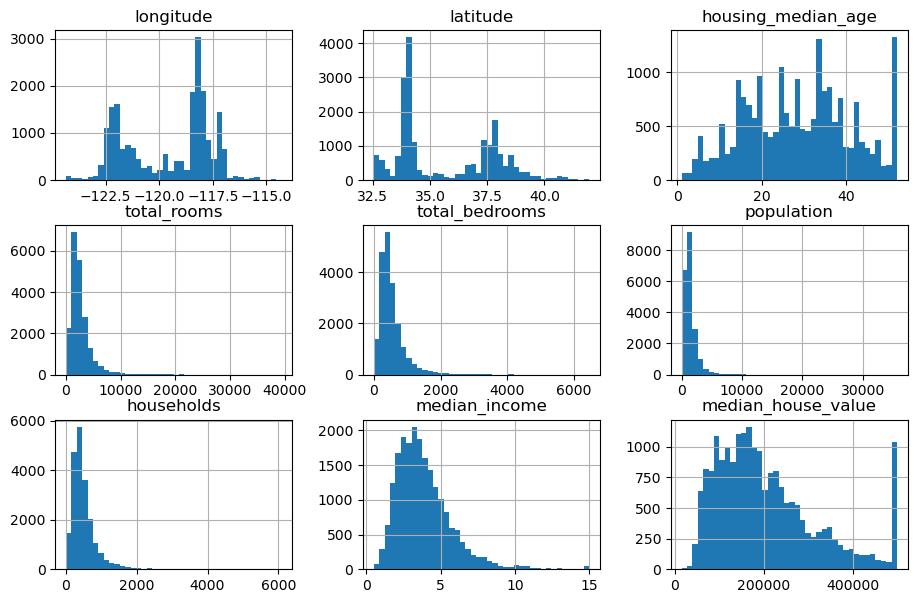

In [571]:
df.hist(figsize=(11,7),bins=40)

In [572]:
df['ocean_proximity'].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [573]:
# برای پیدا کردن اینکه کدام فیچر برای استراتیفای مناسب هستش
# df.corr(numeric_only = True)
df.corr(numeric_only=True)['median_house_value'].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

In [574]:
# تبدیل داده ی پیوسته با همبستگی بیشتر به داده دسته بندی شده
df['median_income_categories'] = pd.cut(df["median_income"], bins=[0,1.5,3,4.5,6,np.inf], labels=[1,2,3,4,5])

In [575]:
df['median_income_categories'].value_counts()

median_income_categories
3    7236
2    6581
4    3639
5    2362
1     822
Name: count, dtype: int64

<Axes: xlabel='median_income_categories'>

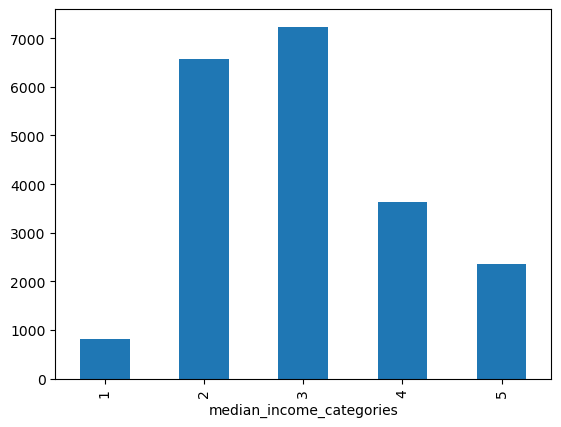

In [576]:
df['median_income_categories'].value_counts().sort_index().plot.bar()

In [577]:
# تقسیم داده به داده آموزش و تست
train_set, test_set  = train_test_split(df, test_size=0.2, random_state=40,stratify=df['median_income_categories'])

In [578]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,median_income_categories
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,5
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,5
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,5
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,4
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,3
...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,2
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,2
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,2
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,2


In [579]:
# حذف داده دسته بندی شده
train_set = train_set.drop("median_income_categories",axis=1)
test_set = test_set.drop("median_income_categories",axis=1)

In [580]:
train_set

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
16415,-121.26,37.88,42.0,465.0,93.0,256.0,93.0,3.1719,158300.0,INLAND
1279,-121.64,37.85,22.0,1999.0,415.0,967.0,320.0,4.4583,253900.0,INLAND
7741,-118.15,33.95,35.0,2753.0,702.0,1592.0,614.0,2.7875,209000.0,<1H OCEAN
4425,-118.24,34.07,27.0,223.0,80.0,249.0,82.0,1.6136,137500.0,<1H OCEAN
1283,-121.82,38.02,46.0,176.0,43.0,101.0,40.0,2.2361,93800.0,INLAND
...,...,...,...,...,...,...,...,...,...,...
1221,-120.65,38.28,21.0,3095.0,681.0,1341.0,546.0,2.1382,104000.0,INLAND
12640,-121.45,38.53,34.0,1893.0,415.0,884.0,395.0,2.1679,75400.0,INLAND
5747,-118.27,34.17,48.0,1560.0,280.0,825.0,269.0,5.5118,354700.0,<1H OCEAN
16224,-121.33,37.98,36.0,3113.0,576.0,1746.0,544.0,3.4625,84600.0,INLAND


In [581]:
# حذف تارگت از دادهای آموزش و تست
train_features = train_set.drop(columns="median_house_value")
train_target = train_set["median_house_value"]

test_features = test_set.drop(columns="median_house_value")
test_target = test_set["median_house_value"]


In [582]:
heavy_tail_pipeine = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log,feature_names_out="one-to-one"),
    StandardScaler()
)

In [583]:
housing_median_age_rbf_transformer = FunctionTransformer(
    rbf_kernel,
     feature_names_out="one-to-one",
     kw_args={"Y":[[35.0]],"gamma":0.1})

In [584]:
#ترکیب فیچرها در پایپ لاین
def ratio_of_columns (x):
    return x[:,[0]] / x[:,[1]]
def ratio_of_columns_names(function_transformer, feature_names_in):
    return ["ratio"]

def ratio_of_columns_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(
                            ratio_of_columns,
                            feature_names_out=ratio_of_columns_names
                             ),
        StandardScaler()
    )

In [585]:
# all_transformations.get_feature_names_out()

In [586]:
train_features_transformed

array([[-2.10670105e-01, -1.79381511e-01, -2.84533255e-02, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-9.60951107e-02,  3.65121948e-01, -3.75641043e-03, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [ 6.17994355e-01, -4.04841051e-01, -4.31193773e-02, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       ...,
       [-5.19759731e-01,  1.69649412e-01,  3.75800155e-04, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-4.36232057e-01,  1.36098158e-01,  1.34628996e-02, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00],
       [-6.90020966e-01,  2.23591409e-01, -1.49734229e-02, ...,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00]],
      shape=(16512, 14))

In [587]:

numerical_features = list(train_features.columns)
numerical_features.remove("ocean_proximity")
numerical_features


['longitude',
 'latitude',
 'housing_median_age',
 'total_rooms',
 'total_bedrooms',
 'population',
 'households',
 'median_income']

In [588]:
numerical_features_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    MinMaxScaler()
    )

In [589]:
categorical_features_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder()
)

In [590]:
all_transformer = ColumnTransformer([
    ("bedrooms",ratio_of_columns_pipeline(),["total_bedrooms","total_rooms"]),
    ("rooms_per_house",ratio_of_columns_pipeline(),["total_rooms","households"]),
    ("people_per_house",ratio_of_columns_pipeline(),["population","households"]),
    ("log",heavy_tail_pipeine,["total_bedrooms","total_rooms","population","households","median_income"]),
    ("rbf",housing_median_age_rbf_transformer,["housing_median_age"]),
    ("cat",categorical_features_pipeline,["ocean_proximity"])
])


In [591]:
train_features_transformed = all_transformer.fit_transform(train_features)

In [592]:
all_transformer.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'rbf__housing_median_age',
       'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND',
       'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY',
       'cat__ocean_proximity_NEAR OCEAN'], dtype=object)

In [593]:
test_features_transformed = all_transformer.transform(test_features)

In [594]:
all_transformer.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'rbf__housing_median_age',
       'cat__ocean_proximity_<1H OCEAN', 'cat__ocean_proximity_INLAND',
       'cat__ocean_proximity_ISLAND', 'cat__ocean_proximity_NEAR BAY',
       'cat__ocean_proximity_NEAR OCEAN'], dtype=object)

In [595]:
Linear_regression_pipeline = make_pipeline(
    all_transformer,
    LinearRegression()
)

In [596]:
Linear_regression_pipeline.fit(train_features,train_target)

,steps,"[('columntransformer', ...), ('linearregression', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [597]:
house_value_perdiction = Linear_regression_pipeline.predict(train_features)

In [598]:
house_value_perdiction

array([141719.01431917, 177631.82957207, 203925.39170766, ...,
       285483.69674784, 132027.37180879, 287262.98253375], shape=(16512,))

In [599]:
train_target.values

array([158300., 253900., 209000., ..., 354700.,  84600., 336000.],
      shape=(16512,))

In [600]:
mean_absolute_error(train_target.values,house_value_perdiction)

54917.463957175765

In [601]:
mean_squared_error(train_target.values,house_value_perdiction)

5394560853.613249

In [602]:
r2_score(train_target.values,house_value_perdiction)

0.5926905813295076

In [603]:
dt_regression_pipeline = make_pipeline(
    all_transformer,
    DecisionTreeRegressor()
)

In [604]:
dt_regression_pipeline.fit(train_features,train_target)

,steps,"[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [605]:
mean_absolute_error(train_target.values,
                    dt_regression_pipeline.predict(train_features))

0.0

In [606]:
r2_score(train_target.values,
                    dt_regression_pipeline.predict(train_features))

1.0

In [607]:
dt_mean = -cross_val_score(dt_regression_pipeline,
                train_features,
                train_target,
                scoring="neg_mean_absolute_error",
                cv=5)

In [608]:
dt_mean

array([58351.48864668, 56876.21313957, 58310.79830406, 58123.39158086,
       58496.96032707])

In [609]:
pd.Series(dt_mean).describe()

count        5.000000
mean     58031.770400
std        659.580363
min      56876.213140
25%      58123.391581
50%      58310.798304
75%      58351.488647
max      58496.960327
dtype: float64

In [610]:
dt_regression_pipeline = Pipeline([
    ("transformation", all_transformer),
    ("dtr", DecisionTreeRegressor())
                                  ]
)

In [611]:
param_grid={"transformation__rbf__kw_args":[{"Y":[[35.0]],"gamma":0.1},
                                            {"Y":[[35.0]],"gamma":0.2}],
            "dtr__max_depth":[5,10,15]}

In [612]:
gs = GridSearchCV(dt_regression_pipeline,
             param_grid,
             scoring="neg_mean_absolute_error",
             cv=5)

In [613]:
gs.fit(train_features,train_target)

,estimator,Pipeline(step...Regressor())])
,param_grid,"{'dtr__max_depth': [5, 10, ...], 'transformation__rbf__kw_args': [{'Y': [[35.0]], 'gamma': 0.1}, {'Y': [[35.0]], 'gamma': 0.2}]}"
,scoring,'neg_mean_absolute_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('bedrooms', ...), ('rooms_per_house', ...), ...]"


In [614]:
housing_model = gs.best_estimator_

In [615]:
housing_model["dtr"].feature_importances_.round(3)

array([0.023, 0.019, 0.136, 0.007, 0.006, 0.007, 0.009, 0.582, 0.03 ,
       0.   , 0.176, 0.001, 0.   , 0.003])

In [616]:
sorted(zip(housing_model["dtr"].feature_importances_.round(3),
       housing_model["transformation"].get_feature_names_out()))

[(np.float64(0.0), 'cat__ocean_proximity_<1H OCEAN'),
 (np.float64(0.0), 'cat__ocean_proximity_NEAR BAY'),
 (np.float64(0.001), 'cat__ocean_proximity_ISLAND'),
 (np.float64(0.003), 'cat__ocean_proximity_NEAR OCEAN'),
 (np.float64(0.006), 'log__total_rooms'),
 (np.float64(0.007), 'log__population'),
 (np.float64(0.007), 'log__total_bedrooms'),
 (np.float64(0.009), 'log__households'),
 (np.float64(0.019), 'rooms_per_house__ratio'),
 (np.float64(0.023), 'bedrooms__ratio'),
 (np.float64(0.03), 'rbf__housing_median_age'),
 (np.float64(0.136), 'people_per_house__ratio'),
 (np.float64(0.176), 'cat__ocean_proximity_INLAND'),
 (np.float64(0.582), 'log__median_income')]

In [617]:
mean_squared_error(test_target,
                   housing_model.predict(test_features),
                   )    

4963380235.652569

In [618]:
ci = 0.95

In [619]:
se = (test_target.values -   housing_model.predict(test_features)) ** 2 

In [620]:
np.sqrt(stats.t.interval(ci,
                 len(se-1),
                 loc=np.mean(se),
                 scale=stats.sem(se)))

array([67439.69811491, 73339.26362785])

In [621]:
joblib.dump(housing_model, "housing_model.pkl")


['housing_model.pkl']

In [622]:
housing_model_model = joblib.load("housing_model.pkl")

In [623]:
housing_model_model

,steps,"[('transformation', ...), ('dtr', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('bedrooms', ...), ('rooms_per_house', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
